In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル・開発環境で実行中。リポジトリルート:", repo_root)


💻 ローカル・開発環境で実行中。リポジトリルート: /home/student/Documents/GitHub/study-mikanos


# 6.4 ポーリングでマウス入力 (`Mouse Input via xHCI Polling`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/6/6.4_Mouse_Input_via_xHCI_Polling.ipynb)
![Language](https://img.shields.io/badge/Language-C%2B%2B20%20%7C%20Python%203.11%2B-blue.svg)
![Target](https://img.shields.io/badge/Target-x86__64%20%7C%20xHCI%20%7C%20USB%20HID-orange.svg)
![Chapter](https://img.shields.io/badge/Chapter-6.4%20(Mouse%20Polling)-green.svg)

---

## 📖 節の概要と学習目標

前節（**第6章 6.3節 / `osbook_day06b`**）では、PCI コンフィギュレーション空間を全探索（`ScanAllBus`）し、マシン上に接続された PCI デバイス一覧から、目標とする **xHCI（*eXtensible Host Controller Interface*）USB 3.0 コントローラ**（Class Code `0x0C0330`）をピンポイントで特定することに成功しました。

しかし、デバイスを特定しただけでは、まだマウスカーソルを動かすことはできません。なぜなら：
1. **MMIO アドレス未取得**: xHCI コントローラの内部レジスタにアクセスするための物理メモリアドレス（BAR0）が未取得であること
2. **ホストコントローラ未初期化**: xHCI コントローラの内部データ構造（DCBAA、Command Ring、Event Ring）がまだメモリ上に配置・起動されていないこと
3. **USB ポート未設定**: 接続されている USB ポートを検出し、USB HID マウスを列挙（Enumeration）・初期設定していないこと
4. **イベント受信ループの欠如**: マウスが移動した際の変位量（`dx`, `dy`）を定期的に受け取る仕組みが存在しないこと

本節（**第6章 6.4節 / `osbook_day06c`**）では、これらの課題をすべて解決し、**「実際にマウスを動かして画面上のマウスカーソルが追従して移動する」** という自作 OS 開発における感動的なマイルストーンを達成します：

- **PCI Base Address Register (BAR0) の数理導出**: 32bit / 64bit MMIO アドレスの判定、下位4bitフラグの安全なマスク処理
- **コラム6.2 の深掘り**: なぜ `static_cast<uint64_t>(0xf)` が必要なのか？ C++ 規格における整数昇格と符号拡張の罠の完全解説
- **Intel チップセット特有のポート切り替え (`SwitchEhci2Xhci`)**: レガシー EHCI (USB 2.0) から xHCI への SuperSpeed / High-Speed ポートの移管
- **xHCI ホストコントローラの初期化と起動**: Capability / Operational レジスタの操作、リングバッファ設定、および `Run()`
- **USB ポート列挙と HID マウスドライバ**: `ConfigurePort()` による Slot / Device Context 設定とオブザーバパターン
- **`MouseCursor` クラスによる消去・再描画**: 旧位置を背景色で消去し、新位置にカーソルを描画する相対移動アルゴリズム
- **ポーリング（Polling）によるイベント処理ループ**: `ProcessEvent()` による Event Ring の周期的デキューと、次章（割り込み）への布石
- **コラム6.1 の解説**: カーネルログ関数（`Log`, `SetLogLevel`）の設計とログレベル（`kError`, `kWarn`, `kInfo`, `kDebug`）の閾値制御


## 1. なぜポーリングでマウス入力を行うのか？（動機と前節までの課題）

現代の OS では、マウスの移動やキーボードの打鍵などのユーザー入力イベントは、ハードウェアが CPU に電気信号を送って処理を割り込ませる **「ハードウェア割り込み（Interrupt）」** によって処理されるのが一般的です。

しかし、MikanOS の現時点（第6章）の段階では、まだ **IDT（*Interrupt Descriptor Table* / 割り込み記述子表）** も **MSI（*Message Signaled Interrupts*）** も設定されていません。これら割り込み機構の構築は非常に複雑であり、第7章で一歩ずつ段階的に構築していきます。

そこで本節では、OS のメインループが能動的かつ連続的に xHCI ホストコントローラの状態を監視しに行く **「ポーリング（Polling）」** 方式を採用します：

```cpp
// kernel/main.cpp のイベント処理ループ
while (1) {
    if (auto err = ProcessEvent(xhc)) {
        Log(kError, "Error while ProcessEvent: %s at %s:%d\n",
            err.Name(), err.File(), err.Line());
    }
}
```

> [!NOTE]
> **ポーリング方式のメリットと限界**:
> - **メリット**: 複雑な CPU 割り込み機構やスタック切り替え、競合回避を実装しなくても、シンプルな無限ループだけでデバイスの動作確認とマウス入力のテストが行える。
> - **限界**: イベントが発生していない間も CPU が 100% の全力でループを空回りするため、発熱と電力消費が激しく、他のタスク（マルチタスク）を実行する余裕が奪われる。この課題が、次章「第7章 割り込みとFIFO」への強力な動機（Motivation）となります。


## 2. PCI Base Address Register (BAR0) と MMIO メモリアドレスの導出

### 2.1 メモリマップド I/O (MMIO) と I/O ポート (PMIO) の役割分担

前節（6.3節）で解説したように、x86-64 アーキテクチャには 2 つのハードウェアアクセス空間が存在します：
1. **I/O ポート空間 (PMIO)**: `0x0000`〜`0xFFFF`（64KiB）の独立空間。`in`/`out` 命令でアクセス。PCI コンフィギュレーション空間の探索（`0x0CF8` / `0x0CFC`）に使用。
2. **メモリ空間 (MMIO)**: CPU の広大な物理アドレス空間（RAM と同じアドレスバス）。通常のポインタ間接参照（`MOV` 命令）で高速に読み書き可能。

xHCI コントローラの無数のレジスタ群（転送リング、ドアベル、ポートステータスなど）は、I/O ポートではなく **MMIO** としてメインメモリの物理アドレス空間上にマッピングされます。
その **「MMIO 領域が物理アドレス空間のどこに配置されているか」** を OS に知らせるのが、PCI コンフィギュレーション空間の **BAR（*Base Address Register* / ベースアドレスレジスタ）** です。

---

### 2.2 PCI BAR のビットレイアウトと 32bit / 64bit アドレス判定数理

Type 00h（一般デバイス）の PCI コンフィギュレーション空間には、オフセット `0x10` から `0x24` まで計 6 個の BAR（BAR0〜BAR5、各32ビット）が存在します。

BAR の下位ビットには、そのメモリ領域の属性を表すフラグが格納されています：

$$
\begin{array}{|c|c|l|}
\hline
\textbf{ビット範囲} & \textbf{フィールド名} & \textbf{意味・仕様} \\
\hline
\text{Bit } 0 & \text{Memory Space Indicator} & 0 = \text{メモリ空間 (MMIO)}, \; 1 = \text{I/Oポート空間 (PMIO)} \\
\hline
\text{Bits } 2:1 & \text{Type} & 00_b = 32\text{ビットアドレス空間}, \; 10_b = 64\text{ビットアドレス空間} \\
\hline
\text{Bit } 3 & \text{Prefetchable} & 1 = \text{投機的プリフェッチ可能}, \; 0 = \text{非プリフェッチ (副作用あり)} \\
\hline
\text{Bits } 31:4 & \text{Base Address} & \text{MMIO ベースアドレスの上位ビット (16バイト境界アライメント)} \\
\hline
\end{array}
$$

#### 64ビット BAR の結合ロジック
Bits 2:1 が $10_b$（値として 4、マスク `bar & 4u`）の場合、このデバイスは **64ビットアドレス** を使用します。
このとき、**BAR0 が下位 32 ビット**、次の **BAR1 が上位 32 ビット** を格納するため、2 つの 32 ビットレジスタを結合して 64 ビット物理アドレスを構成します：

$$
\text{BaseAddress}_{64} = \text{BAR0} \;\vert\; \left(\text{static\_cast<uint64\_t>}(\text{BAR1}) \ll 32\right)
$$

#### 下位 4 ビットのフラグクリア
BAR0 の下位 4 ビット（Bits 3:0）は属性フラグであるため、純粋な物理 MMIO ベースアドレスを得るには、下位 4 ビットをゼロクリアする必要があります：

$$
\text{MMIO\_Base} = \text{BaseAddress}_{64} \;\&\; \sim\text{static\_cast<uint64\_t>}(0\text{xF})
$$


## 3. コラム6.2: static_cast<uint64_t>(0xf) の謎（整数昇格と符号拡張の罠）

> [!IMPORTANT]
> **コラム6.2 の核心**: なぜ単に `~0xf` と書かずに、わざわざ `~static_cast<uint64_t>(0xf)` とキャストしてから反転しているのでしょうか？

C++（および C言語）の型システムとビット演算には、初学者が極めて陥りやすい **「整数昇格（Integer Promotion）」** と **「符号拡張（Sign Extension）」** の落とし穴が存在します。

### 3.1 危険な記述: `~0xf` の挙動ステップ
1. **リテラル `0xf` の型**: C++ において、サフィックスのない `0xf` は **32ビット符号付き整数 `int`**（`0x0000000F`）とみなされます。
2. **ビット反転演算 `~0xf`**: 32ビット `int` の全ビットが反転し、`0xFFFFFFF0` となります。最上位ビット（Bit 31）が 1 であるため、これは 2の補数表現で **`-16`**（負の数）となります。
3. **64ビット `uint64_t` との `&` 演算**: 64ビットの変数（`xhc_bar.value`）と演算する際、32ビット符号付き `int`（`-16`）は 64ビットに型変換されます。このとき、**符号付き整数は負の符号を維持するために上位ビットがすべて 1 で埋められる（符号拡張 / Sign Extension）** ため、結果として `0xFFFFFFFFFFFFFFF0ULL` になることがあります。

### 3.2 なぜこれがバグの温床となるのか？
- コンパイラや最適化オプションによっては、「符号付き整数のビット反転」や「符号付き/符号なしの暗黙の混在演算」に対して **コンパイル警告（`-Wsign-conversion`, `-Wconversion`）** が発生します。
- もし型が意図せず 32ビット符号なし `uint32_t` だった場合、ゼロ拡張（Zero Extension）されて上位 32 ビットが `0x00000000` となり、**64ビットアドレスの上位半分がすべて消し飛ぶ（0クリアされる）** という致命的なハードウェアアクセス障害を引き起こします！

### 3.3 安全な正規コードの数理
```cpp
const uint64_t xhc_mmio_base = xhc_bar.value & ~static_cast<uint64_t>(0xf);
```
先に `static_cast<uint64_t>(0xf)` を行うことで：
1. `0x000000000000000FULL`（64ビット符号なし整数）に明示的に拡張される。
2. これを反転 `~` することで、厳密に `0xFFFFFFFFFFFFFFF0ULL`（64ビット符号なし整数）が生成される。
3. 符号拡張の曖昧さやコンパイラ依存性が 100% 排除され、64ビット MMIO ベースアドレスの下位 4 ビットのみが安全確実にマスク・クリアされる。


In [2]:
# === Python による PCI BAR0 レジスタデコード & コラム6.2 の検証 ===
from common import PCIBAR

# 例1: QEMU / 実機における 64-bit xHCI BAR0 の値 (例: 0xFEA00004, Upper: 0x00000001)
# Bit 2 is 1 (Type = 10b -> 64-bit), Lower 4 bits = 0x4 (Memory space, 64-bit, non-prefetchable)
bar64 = PCIBAR(raw_lower=0xFEA00004, raw_upper=0x00000001, bar_index=0)

print(f"Raw Combined (BAR0+BAR1): 0x{bar64.raw_combined:016X}")
print(f"Is MMIO: {bar64.is_mmio}, Is 64-bit: {bar64.is_64bit}, Prefetchable: {bar64.is_prefetchable}")
print(f"Physical MMIO Base Address: 0x{bar64.base_address:016X}")

# コラム6.2 の解説辞書を出力
mystery = PCIBAR.explain_static_cast_mystery()
print("\n--- コラム6.2: static_cast<uint64_t>(0xf) の数理 ---")
for k, v in mystery.items():
    print(f"{k}: {v}")


Raw Combined (BAR0+BAR1): 0x00000001FEA00004
Is MMIO: True, Is 64-bit: True, Prefetchable: False
Physical MMIO Base Address: 0x00000001FEA00000

--- コラム6.2: static_cast<uint64_t>(0xf) の数理 ---
issue: In C++, literal `0xf` has type `int` (signed 32-bit). Bitwise NOT `~0xf` produces `0xFFFFFFF0` (signed int, value -16). When operating with 64-bit uint64_t, sign extension or narrowing conversion can produce subtle platform-dependent bugs or compiler warnings. By casting to uint64_t first: static_cast<uint64_t>(0xf) == 0x000000000000000FULL, then taking ~ produces 0xFFFFFFFFFFFFFFF0ULL, safely clearing only the lowest 4 bits.
literal_0xf: int (32-bit signed): 0x0000000F
tilde_literal: int (32-bit signed): 0xFFFFFFF0
cast_then_tilde: uint64_t (64-bit unsigned): 0xFFFFFFFFFFFFFFF0


## 4. 高解像度アーキテクチャ図版: PCI BAR と MMIO 空間マッピング (Figure 6.07)

以下の図版は、PCI コンフィギュレーション空間における BAR0 レジスタのビットレイアウト、コラム6.2 で解説した `static_cast<uint64_t>(0xf)` による安全なマスク処理、および CPU 物理メモリマップにおける xHCI MMIO レジスタ空間の配置を完全に視覚化したものです：

- **Top-Left**: PCI BAR レジスタ（32ビット）のビットフィールドレイアウト（Base Address, PF, Type, Memory Space Indicator）
- **Bottom-Left**: `~0xf` の符号拡張トラップ vs `~static_cast<uint64_t>(0xf)` の安全性数理
- **Right**: 64ビット物理メモリ空間における DRAM（RAM）、32bit PCI MMIO ホール、および xHCI MMIO レジスタ領域のマッピング関係


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:23201: UserWarning: Glyph 12304 (\N{LEFT BLACK LENTICULAR BRACKET}) missing from font(s) DejaVu Sans.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:23201: UserWarning: Glyph 12499 (\N{KATAKANA LETTER BI}) missing from font(s) DejaVu Sans.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:23201: UserWarning: Glyph 12483 (\N{KATAKANA LETTER SMALL TU}) missing from font(s) DejaVu Sans.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:23201: UserWarning: Glyph 12488 (\N{KATAKANA LETTER TO}) missing from font(s) DejaVu Sans.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:23201: UserWarning: Glyph 12524 (\N{KATAKANA LETTER RE}) missing from font(s) Dej

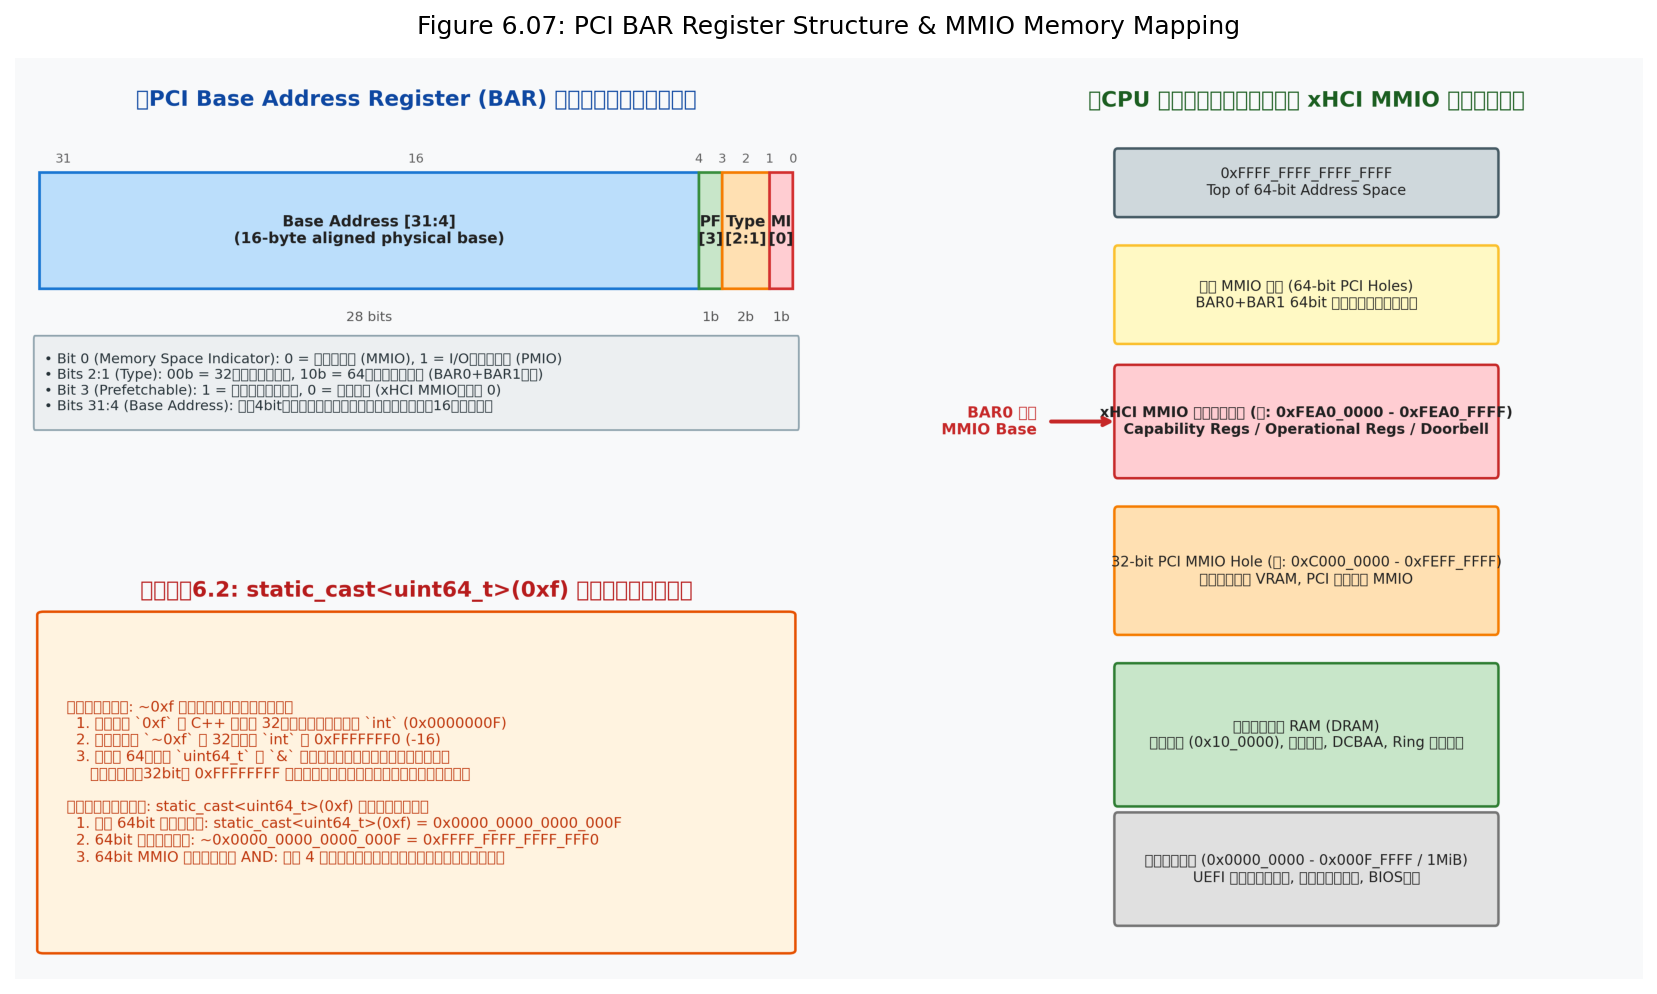

In [3]:
# === Figure 6.07: PCI BAR レジスタ構造と MMIO マッピング図版生成 ===
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
from common import plot_fig6_07_pci_bar_and_mmio_mapping

fig_path = Path(repo_root) / "6" / "result" / "fig6_07_pci_bar_and_mmio_mapping.png"
plot_fig6_07_pci_bar_and_mmio_mapping(str(fig_path))

plt.figure(figsize=(14, 8), dpi=150)
img = Image.open(fig_path)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 6.07: PCI BAR Register Structure & MMIO Memory Mapping", fontsize=12, pad=12)
plt.show()


## 5. Intel チップセットのポート切り替えと xHCI コントローラの初期化

### 5.1 Intel チップセット特有のポート切り替え (`SwitchEhci2Xhci`)

Intel 製チップセット（Vendor ID `0x8086`, 例: Panther Point 等）を搭載した実機や仮想環境では、歴史的経緯（後方互換性）により、**USB 2.0 ポートがデフォルトで旧世代の EHCI コントローラに物理配線（ルーティング）されている** という特殊な仕様があります。

このままでは、xHCI コントローラから USB ポートにアクセスすることができません。そこで、PCI コンフィギュレーション空間の Intel 固有拡張レジスタを操作し、全 USB ポートの制御権を EHCI から xHCI へ移管（ハンドオーバ）します：

```cpp
// kernel/main.cpp
void SwitchEhci2Xhci(const pci::Device& xhc_dev) {
    bool intel_ehc_exist = false;
    for (int i = 0; i < pci::num_device; ++i) {
        if (pci::devices[i].class_code.Match(0x0cu, 0x03u, 0x20u) /* EHCI */ &&
            0x8086 == pci::ReadVendorId(pci::devices[i])) {
            intel_ehc_exist = true;
            break;
        }
    }
    if (!intel_ehc_exist) return;

    uint32_t superspeed_ports = pci::ReadConfReg(xhc_dev, 0xdc); // USB3PRM
    pci::WriteConfReg(xhc_dev, 0xd8, superspeed_ports);          // USB3_PSSEN
    uint32_t ehci2xhci_ports = pci::ReadConfReg(xhc_dev, 0xd4);  // XUSB2PRM
    pci::WriteConfReg(xhc_dev, 0xd0, ehci2xhci_ports);           // XUSB2PR
    Log(kDebug, "SwitchEhci2Xhci: SS = %02x, xHCI = %02x\n",
        superspeed_ports, ehci2xhci_ports);
}
```

### 5.2 xHCI コントローラの初期化と実行開始 (`xhc.Initialize()` & `xhc.Run()`)

取得した MMIO ベースアドレスを用いて `usb::xhci::Controller` インスタンスを生成し、前節（6.2節）で学んだデータ構造をメモリ上に構築します：

1. **`xhc.Initialize()`**:
   - ホストコントローラのリセット（USBCMD の HCRST ビット）
   - **DCBAA（*Device Context Base Address Array*）** のメモリ確保とレジスタ（DCBAAP）への物理アドレス登録
   - **Command Ring** のメモリ確保とレジスタ（CRCR）への登録
   - **Primary Interrupter**（Event Ring Segment Table, ERST / ERDP）の初期設定
2. **`xhc.Run()`**:
   - USBCMD（USB Command Register）の Run/Stop ビット（Bit 0）を 1 にセットし、xHCI ハードウェアエンジンを動作開始（RUN 状態）にします。


## 6. USB ポート検出・設定と HID マウスドライバ (`ConfigurePort`)

xHCI コントローラが RUN 状態になったら、コントローラが備える各物理ポート（`1`〜`xhc.MaxPorts()`）を走査してデバイスが挿入されているかを確認します：

```cpp
usb::HIDMouseDriver::default_observer = MouseObserver;

for (int i = 1; i <= xhc.MaxPorts(); ++i) {
    auto port = xhc.PortAt(i);
    Log(kDebug, "Port %d: IsConnected=%d\n", i, port.IsConnected());

    if (port.IsConnected()) {
        if (auto err = ConfigurePort(xhc, port)) {
            Log(kError, "failed to configure port: %s at %s:%d\n",
                err.Name(), err.File(), err.Line());
            continue;
        }
    }
}
```

### 6.1 `ConfigurePort` の内部シーケンス
1. **ポートリセット（Port Reset）**: 接続を検出したポートに対してリセット信号を発行し、通信速度（SuperSpeed, High, Full, Low）をネゴシエーションします。
2. **Enable Slot Command**: xHCI に対して `EnableSlotCommandTRB` を発行し、デバイスに割り当てる一意の **Slot ID** を取得します。
3. **Device Context の初期化**: デバイスの通信コンテキスト（Slot Context, Endpoint 0 Context）を構築します。
4. **Address Device Command**: デバイスに USB アドレスを割り当て、デフォルトコントロールパイプ（EP0）を開きます。
5. **デスクリプタ読み出し**: デバイスデスクリプタ、コンフィギュレーションデスクリプタを読み出し、Interface Class が `0x03`（HID）、Protocol が `0x02`（Mouse）であることを認識します。
6. **HID マウスドライバのバインド**: `usb::HIDMouseDriver` を生成し、割り込みエンドポイント（Interrupt IN Endpoint）への転送リクエスト（TRB）をキューイングしてマウス移動データの待機を開始します。


## 7. MouseCursor クラスの設計と相対移動描画 (`MoveRelative`)

6.1節（`osbook_day06a`）では、静的な関数 `DrawMouseCursor` を用いて固定座標にマウスカーソルを描画していました。
本節では、マウスの移動に応じてカーソルを動かすため、状態（現在位置 `position_`、消去色 `erase_color_`）をカプセル化した **`MouseCursor` クラス**（`kernel/mouse.hpp`, `kernel/mouse.cpp`）を新設します。

### 7.1 なぜ「消去」が必要なのか？
フレームバッファ（VRAM）はピクセル値の二次元配列です。カーソルが $(x, y)$ から $(x + dx, y + dy)$ へ移動した際、単に新座標にカーソルを描画するだけでは、**旧座標に描かれたカーソルがそのまま画面に残ってしまい、マウスの軌跡が消えずに画面を塗りつぶしてしまう** という問題が生じます。

### 7.2 相対移動アルゴリズムの 3 ステップ
```cpp
void MouseCursor::MoveRelative(Vector2D<int> displacement) {
    // 1. 旧位置のカーソルを背景色で上書き消去
    EraseMouseCursor(pixel_writer_, position_, erase_color_);
    // 2. 相対変位ベクトルを加算して現在座標を更新
    position_ += displacement;
    // 3. 新位置にカーソルスプライトを描画
    DrawMouseCursor(pixel_writer_, position_);
}
```

> [!NOTE]
> **消去処理の限界（重ね合わせの課題）**:
> 現在の `EraseMouseCursor` は、カーソルのあった矩形領域を一律に単一の背景色（`kDesktopBGColor`）で塗りつぶします。
> この方式では、デスクトップ背景の上を移動する分には問題ありませんが、**ウィンドウや文字の上にカーソルが重なると、マウスが通過した箇所の文字やウィンドウが背景色で消し去られてしまう** という深刻な問題が発生します。
> この問題を完全に解決するのが、後の **第9章「重ね合わせ処理（Layer Manager）」** です！


## 8. メインループにおけるイベントポーリング (`ProcessEvent`)

カーネルの初期化が完了すると、`KernelMain` は無限ループに入り、xHCI コントローラのイベントリングを継続的に検査します：

```cpp
// kernel/main.cpp
while (1) {
    if (auto err = ProcessEvent(xhc)) {
        Log(kError, "Error while ProcessEvent: %s at %s:%d\n",
            err.Name(), err.File(), err.Line());
    }
}
```

### 8.1 `ProcessEvent()` のイベントディスパッチ機構
1. **`HasFront()` による未処理判定**: プライマリイベントリングのデキューポインタ（ERDP）を調べ、未処理の Event TRB が存在するか確認します。イベントがなければ即座に `kSuccess` を返します（ノンブロッキング）。
2. **TRB の動的キャストと分岐**: イベントが存在する場合、TRB の Type を判定します：
   - `TransferEventTRB`: データ転送完了（マウスの割り込み転送パケット到着など）
   - `PortStatusChangeEventTRB`: USB ポートへの機器抜き差しイベント
   - `CommandCompletionEventTRB`: コマンドリングに発行したコマンドの完了通知
3. **オブザーバの呼び出し**: マウスの転送完了イベントの場合、8バイトの入力レポート（Buttons, Displacement X, Displacement Y）がデコードされ、登録済みの `MouseObserver` 関数が呼び出されます：

```cpp
void MouseObserver(int8_t displacement_x, int8_t displacement_y) {
    mouse_cursor->MoveRelative({displacement_x, displacement_y});
}
```


## 9. 高解像度アーキテクチャ図版: xHCI 初期化とポーリングイベントフロー (Figure 6.08)

以下の図版は、`KernelMain`、`usb::xhci::Controller`、USB ポート/デバイス、および `MouseCursor` 間の初期化シーケンスと、メインループにおけるポーリングイベント処理・消去・再描画のデータフローを完全に視覚化したものです：

- **Left (Sequence Diagram)**: コントローラ初期化からポート設定、マウスカーソル生成、イベントリング検査、`MouseObserver` コールバックまでの 10 段階の制御シーケンス
- **Right (Data Flow)**: メインループ内のポーリング判定、TRB デコード、変位ベクトル伝達、および旧座標消去・座標加算・新座標描画の 3 段階描画フロー


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:23296: UserWarning: Glyph 12304 (\N{LEFT BLACK LENTICULAR BRACKET}) missing from font(s) DejaVu Sans.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:23296: UserWarning: Glyph 21021 (\N{CJK UNIFIED IDEOGRAPH-521D}) missing from font(s) DejaVu Sans.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:23296: UserWarning: Glyph 26399 (\N{CJK UNIFIED IDEOGRAPH-671F}) missing from font(s) DejaVu Sans.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:23296: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:23296: UserWarning: Glyph 12392 (\N{HIRAGANA LETTER TO}) missin

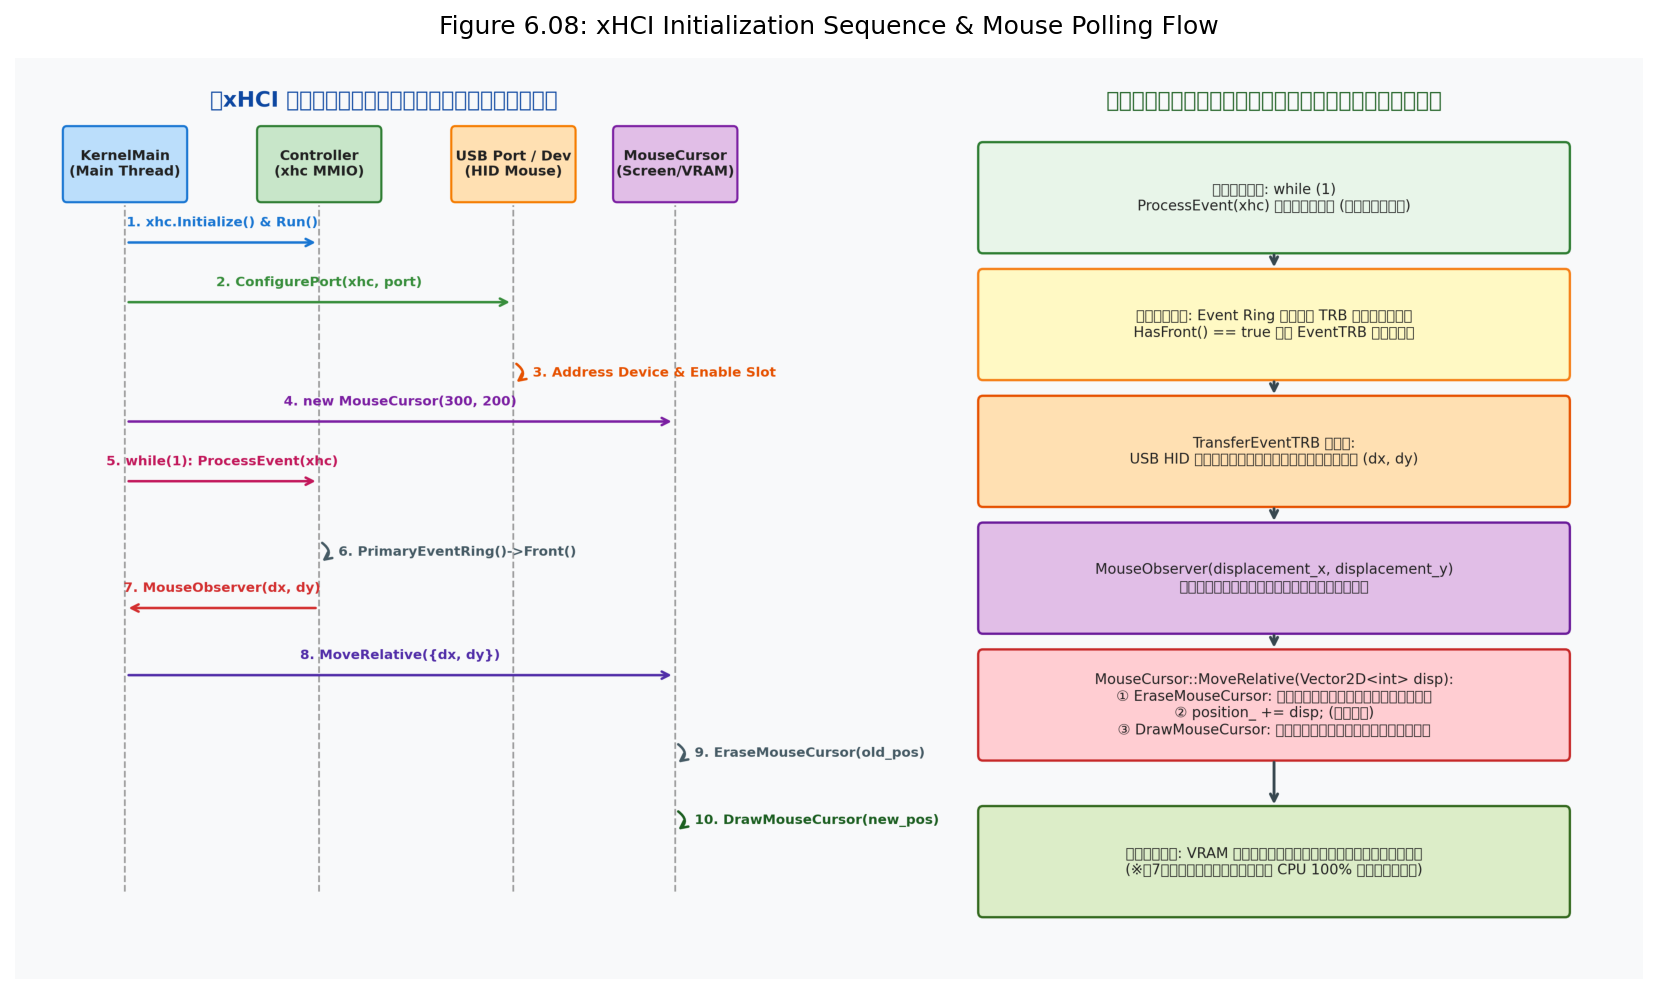

In [4]:
# === Figure 6.08: xHCI 初期化とポーリングイベント処理図版生成 ===
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
from common import plot_fig6_08_xhci_polling_sequence_and_mouse_event_flow

fig_path2 = Path(repo_root) / "6" / "result" / "fig6_08_xhci_polling_sequence_and_mouse_event_flow.png"
plot_fig6_08_xhci_polling_sequence_and_mouse_event_flow(str(fig_path2))

plt.figure(figsize=(14, 8), dpi=150)
img2 = Image.open(fig_path2)
plt.imshow(img2)
plt.axis("off")
plt.title("Figure 6.08: xHCI Initialization Sequence & Mouse Polling Flow", fontsize=12, pad=12)
plt.show()


## 10. コラム6.1: カーネルログ関数 (`Log`, `SetLogLevel`)

第5章で実装した `printk()` は、渡された文字列を無条件に画面コンソールへ出力していました。
しかし、USB ドライバのように大量のハードウェア通信が発生するサブシステムでは、すべてのデバッグメッセージを出力していると、**画面がログで埋め尽くされ、カーソル描画が著しく遅延し、重要なエラーメッセージを見落とす** という問題が発生します。

そこで、Linux や BSD などの実用 OS に倣い、優先度（ログレベル）によるフィルタリング機構を備えたカーネルログシステム（`kernel/logger.hpp`, `kernel/logger.cpp`）を導入します。

### 10.1 ログレベルの定義と優先度しきい値
```cpp
enum LogLevel {
    kError = 3,  // エラー: 処理の継続が困難な障害
    kWarn  = 4,  // 警告: 予期せぬ状態だが処理は継続可能
    kInfo  = 6,  // 情報: 機器検出などの通常通知
    kDebug = 7,  // デバッグ: 開発用の詳細な内部ログ
};
```

- 数値が小さいほど重大度（優先度）が高くなります。
- `SetLogLevel(level)` で設定した **しきい値（閾値）以下の優先度値**（しきい値以上の重要度）を持つメッセージのみが `console->PutString()` に送られ、それ以外の詳細ログは即座に破棄されます。
- `KernelMain` の冒頭では `SetLogLevel(kWarn)` と設定されているため、`kDebug` や `kInfo` のログは画面に出力されず、警告やエラーのみが表示されます。


In [5]:
# === Python によるカーネルロガー & マウス移動シミュレーション ===
from common import LogLevel, KernelLogger, MouseMovementSimulator, XHCIPollingSimulator

# 1. カーネルロガーの検証
logger = KernelLogger(level=LogLevel.WARN)
print("=== ログレベルフィルタリング検証 (しきい値: kWarn) ===")
print("Log(kError):", logger.log(LogLevel.ERROR, "Host controller reset failed"))  # 出力される
print("Log(kWarn):", logger.log(LogLevel.WARN, "Port reset timed out"))           # 出力される
print("Log(kInfo):", logger.log(LogLevel.INFO, "xHC has been found: 0.4.0"))      # 抑制される
print("Log(kDebug):", logger.log(LogLevel.DEBUG, "Transfer ring cycle bit toggled")) # 抑制される
print(f"記録されたログ件数: {len(logger.logs)} 件 (期待値: 2件)\n")

# 2. マウス相対移動シミュレーション
mouse = MouseMovementSimulator(fb_width=800, fb_height=600, initial_pos=(300, 200))
print(f"初期カーソル座標: {mouse.current_position}")

# マウスを右下へ (+15, +10)、左上へ (-5, -8) 移動
mouse.move_relative(15, 10)
print(f"第1回移動後座標: {mouse.current_position}, 消去座標: {mouse.erased_positions[-1]}")

mouse.move_relative(-5, -8)
print(f"第2回移動後座標: {mouse.current_position}, 消去座標: {mouse.erased_positions[-1]}")

# 3. xHCI ポーリングエミュレータの検証
xhc_sim = XHCIPollingSimulator(mmio_base=0xFEA00000)
xhc_sim.initialize()
xhc_sim.run()
xhc_sim.queue_mouse_packet(10, 5)
xhc_sim.queue_mouse_packet(-3, 2)

print("\n=== xHCI ポーリングループ実行 ===")
processed = xhc_sim.poll_all()
print(f"処理されたイベント数: {processed} 件")
print(f"オブザーバに配送された変位: {xhc_sim.observer_events}")


=== ログレベルフィルタリング検証 (しきい値: kWarn) ===
Log(kError): True
Log(kWarn): True
Log(kInfo): False
Log(kDebug): False
記録されたログ件数: 2 件 (期待値: 2件)

初期カーソル座標: (300, 200)
第1回移動後座標: (315, 210), 消去座標: (300, 200)
第2回移動後座標: (310, 202), 消去座標: (315, 210)

=== xHCI ポーリングループ実行 ===
処理されたイベント数: 2 件
オブザーバに配送された変位: [(10, 5), (-3, 2)]


## 11. C++20 コアロジックの対話型コンパイル & 検証

MikanOS の `kernel/mouse.cpp`, `kernel/logger.cpp`, `kernel/pci.cpp` の実装ロジックをホスト側 C++20（`src/ch06/mouse_polling_sim.cpp`）として切り出し、対話型にコンパイル・実行して全単体テストを実証します：

1. **`TestBarAddressCalculation`**: BAR0 の 32bit / 64bit レジスタデコードと MMIO ベースアドレス抽出数理
2. **`TestStaticCastColumnMystery`**: コラム6.2 の `static_cast<uint64_t>(0xf)` と符号拡張安全性の検証
3. **`TestKernelLoggerFiltering`**: コラム6.1 の優先度レベルフィルタリング動作
4. **`TestMouseCursorMoveRelativeAndErase`**: 旧位置の消去と新位置へのカーソル描画
5. **`TestXHCIPollingEventLoop`**: ノンブロッキングポーリングループとオブザーバ配送


In [6]:
# === C++20 スタンドアロン検証コードの実行 ===
import subprocess
from pathlib import Path

bin_path = Path(repo_root) / "build" / "bin" / "ch06_mouse_polling_sim"
if not bin_path.exists():
    cpp_src = Path(repo_root) / "src" / "ch06" / "mouse_polling_sim.cpp"
    subprocess.run(
        ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", str(cpp_src), "-o", "/tmp/ch06_mouse_polling_sim"],
        check=True
    )
    bin_path = Path("/tmp/ch06_mouse_polling_sim")

print(f"Executing {bin_path} --test:\n")
res = subprocess.run([str(bin_path), "--test"], capture_output=True, text=True, check=True)
print(res.stdout)


Executing /home/student/Documents/GitHub/study-mikanos/build/bin/ch06_mouse_polling_sim --test:

Running Chapter 6.4 Mouse Input via xHCI Polling Standalone Tests...
[PASS] TestBarAddressCalculation: 32-bit & 64-bit BAR math verified.
[PASS] TestStaticCastColumnMystery: static_cast<uint64_t>(0xf) verified.
[PASS] TestKernelLoggerFiltering: Logger thresholds verified.
[PASS] TestMouseCursorMoveRelativeAndErase: Movement and background restore verified.
[PASS] TestXHCIPollingEventLoop: Polling event loop and cursor observer verified.

All Chapter 6.4 mouse polling simulation tests PASSED successfully!



## 12. 第6章 6.4節の総括と次節（第7章 割り込みとFIFO）への展望

### 12.1 本節で達成したことの総括
本節（第6章 6.4節 / `osbook_day06c`）を通じて、私たちは以下の低レイヤ OS アーキテクチャを完全に習得し、実装しました：

1. **PCI BAR の完全理解**: 32bit / 64bit レジスタ構造、フラグビットの数理、および下位4bitの安全なマスク処理
2. **コラム6.2 の深掘り**: C++ における整数昇格・符号拡張の落とし穴と `static_cast<uint64_t>(0xf)` の必然性
3. **xHCI ホストコントローラの起動**: MMIO レジスタ操作、DCBAA・リングバッファの初期化、USB ポート列挙と HID マウスの検出
4. **MouseCursor クラスの実現**: 背景色消去（`EraseMouseCursor`）と相対移動（`MoveRelative`）による画面上でのマウスカーソル移動
5. **コラム6.1 の導入**: ログレベル（`kError`, `kWarn`, `kInfo`, `kDebug`）によるフィルタリングとカーネルデバッグ手法の確立

---

### 12.2 次章「第7章 割り込みとFIFO」への展望

本節でマウスカーソルが動くようになったとはいえ、現在の実装には **重大な構造的欠陥** が残されています：

1. **CPU 100% 負荷（ビジーループ）**: メインスレッドが `while (1) { ProcessEvent(xhc); }` で空回りし続けるため、CPU の電力を浪費し、他の処理を実行できません。
2. **イベントの取りこぼしと遅延**: メインスレッドで重い処理（画面の全画面再描画など）を行っている最中は、ポーリングが止まるため、マウスの移動イベントを取りこぼしたり、カーソル移動がカクつく原因になります。

次章 **「第7章 割り込みとFIFO」** では、ハードウェア側から CPU に通知を送る **IDT（割り込み記述子表）** と **MSI（Message Signaled Interrupts）** を構築し、イベントを高速に一時保存する **リングバッファ（FIFOキュー）** を導入することで、OS を真の **「イベント駆動型アーキテクチャ」** へと進化させます！
